In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms, models
import pandas as pd
from PIL import Image
import os
from tqdm import tqdm
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
import random
import pickle
from sklearn.model_selection import ParameterGrid

In [ ]:
BASE_PATH = '/content/drive/My Drive/findit/dac-findit(nino)'
TRAIN_DIR = os.path.join(BASE_PATH, 'train')
TEST_DIR = os.path.join(BASE_PATH, 'test')
SAMPLE_SUB = os.path.join(BASE_PATH, 'samplesubmission.csv')

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
EPOCHS = 10
LR = 1e-4
IMG_SIZE = 224

print(f"Using device: {DEVICE}")

Using device: cuda


In [ ]:
class FaceTestDataset(Dataset):
    def __init__(self, img_dir, sample_sub_path, transform=None):
        self.img_dir = img_dir
        self.df = pd.read_csv(sample_sub_path)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_id = str(self.df.iloc[idx, 0]).strip()
        img_path = None
        for ext in ['.jpg', '.jpeg', '.png']:
            path = os.path.join(self.img_dir, img_id + ext)
            if os.path.exists(path):
                img_path = path
                break

        if img_path is None:
            image = Image.new('RGB', (IMG_SIZE, IMG_SIZE))
        else:
            image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)
        return image, img_id

In [ ]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [ ]:
from torchvision.datasets import ImageFolder
train_ds = ImageFolder(root=TRAIN_DIR, transform=train_transform)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

idx_to_class = {v: k for k, v in train_ds.class_to_idx.items()}
print(f"Classes: {idx_to_class}")
print(f"Total training samples: {len(train_ds)}")

Classes: {0: 'fake_mannequin', 1: 'fake_mask', 2: 'fake_printed', 3: 'fake_screen', 4: 'fake_unknown', 5: 'realperson'}
Total training samples: 1652


In [ ]:
def evaluate_model(model, loader):
    """Evaluate model accuracy"""
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    return correct / total

def train_model(model, name, params=None, train_loader=None, val_loader=None, return_history=False):
    """
    Train model with configurable hyperparameters
    """
    print(f"\n--- Training Model: {name} ---")
    model = model.to(DEVICE)

    # Use provided parameters or default values
    if params is None:
        lr = LR
        epochs = EPOCHS
        label_smoothing = 0.1
        optimizer_type = 'AdamW'
    else:
        lr = params.get('learning_rate', LR)
        epochs = params.get('epochs', EPOCHS)
        label_smoothing = params.get('label_smoothing', 0.1)
        optimizer_type = params.get('optimizer', 'AdamW')

    # Setup optimizer
    if optimizer_type == 'AdamW':
        optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    else:
        optimizer = optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)

    criterion = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    scaler = torch.cuda.amp.GradScaler()

    # Use provided train_loader or default
    if train_loader is None:
        train_loader = globals()['train_loader']

    train_losses = []
    val_accuracies = []
    best_val_acc = 0
    patience_counter = 0
    early_stop_patience = 5
    best_model_state = None

    for epoch in range(epochs):
        model.train()
        loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")
        running_loss = 0.0

        for images, labels in loop:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with torch.cuda.amp.autocast():
                outputs = model(images)
                loss = criterion(outputs, labels)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            running_loss += loss.item()
            loop.set_postfix(loss=loss.item())

        avg_loss = running_loss / len(train_loader)
        train_losses.append(avg_loss)

        # Validation if val_loader provided
        if val_loader:
            val_acc = evaluate_model(model, val_loader)
            val_accuracies.append(val_acc)
            print(f"Epoch {epoch+1}: Loss={avg_loss:.4f}, Val Acc={val_acc:.4f}")

            # Early stopping
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                patience_counter = 0
                best_model_state = model.state_dict().copy()
            else:
                patience_counter += 1
                if patience_counter >= early_stop_patience:
                    print(f"Early stopping at epoch {epoch+1}")
                    break
        else:
            print(f"Epoch {epoch+1}: Loss={avg_loss:.4f}")

    # Load best model if validation was performed
    if val_loader and best_model_state is not None:
        model.load_state_dict(best_model_state)
        print(f"Best validation accuracy: {best_val_acc:.4f}")

    if return_history:
        return model, train_losses, val_accuracies
    return model

In [ ]:
# Split data untuk training dan validation (80% train, 20% validation)
train_size = int(0.8 * len(train_ds))
val_size = len(train_ds) - train_size
train_subset, val_subset = random_split(train_ds, [train_size, val_size])

# Create validation loader
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print(f"Training samples: {train_size}, Validation samples: {val_size}")

Training samples: 1321, Validation samples: 331


In [ ]:
print("\n" + "="*60)
print("TRAINING BASELINE MODELS")
print("="*60)

# Train ResNet50 baseline
m1 = models.resnet50(weights='IMAGENET1K_V1')
m1.fc = nn.Linear(m1.fc.in_features, 6)
m1 = train_model(m1, "ResNet50_Baseline")

# Train EfficientNet-V2-S baseline
m2 = models.efficientnet_v2_s(weights='IMAGENET1K_V1')
m2.classifier[1] = nn.Linear(m2.classifier[1].in_features, 6)
m2 = train_model(m2, "EfficientNet-V2-S_Baseline")


TRAINING BASELINE MODELS
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 198MB/s]



--- Training Model: ResNet50_Baseline ---


/tmp/ipykernel_3948/4071481336.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()
Epoch 1/10:   0%|          | 0/52 [00:00<?, ?it/s]/tmp/ipykernel_3948/4071481336.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/10: 100%|██████████| 52/52 [09:05<00:00, 10.49s/it, loss=0.639]


Epoch 1: Loss=0.8370


Epoch 2/10: 100%|██████████| 52/52 [01:00<00:00,  1.16s/it, loss=0.469]


... (35 outputs left out)

Epoch 9/10: 100%|██████████| 52/52 [01:02<00:00,  1.20s/it, loss=0.433]


Epoch 9: Loss=0.4579


Epoch 10/10: 100%|██████████| 52/52 [01:04<00:00,  1.24s/it, loss=0.455]

Epoch 10: Loss=0.4526


In [ ]:
# Define hyperparameter search space
param_dist = {
    'batch_size': [16, 32, 64],
    'learning_rate': [1e-5, 5e-5, 1e-4, 5e-4],
    'epochs': [5, 10, 15],
    'optimizer': ['AdamW', 'SGD'],
    'label_smoothing': [0.0, 0.05, 0.1]
}

def random_search(model_class, model_name, param_dist, n_iter=5, train_subset=None, val_loader=None):
    """Perform random search for hyperparameter tuning"""

    best_score = 0
    best_params = None
    best_model = None
    results = []

    for i in range(n_iter):
        # Sample random parameters
        params = {
            'batch_size': random.choice(param_dist['batch_size']),
            'learning_rate': random.choice(param_dist['learning_rate']),
            'epochs': random.choice(param_dist['epochs']),
            'optimizer': random.choice(param_dist['optimizer']),
            'label_smoothing': random.choice(param_dist['label_smoothing'])
        }

        print(f"\n{'='*50}")
        print(f"Trial {i+1}/{n_iter} for {model_name}")
        print(f"Parameters: {params}")
        print('='*50)

        # Create dataloader with current batch size
        train_loader_tune = DataLoader(train_subset, batch_size=params['batch_size'],
                                       shuffle=True, num_workers=2)

        # Initialize model
        if model_class == 'resnet50':
            model = models.resnet50(weights='IMAGENET1K_V1')
            model.fc = nn.Linear(model.fc.in_features, 6)
        else:  # efficientnet
            model = models.efficientnet_v2_s(weights='IMAGENET1K_V1')
            model.classifier[1] = nn.Linear(model.classifier[1].in_features, 6)

        # Train model with current parameters
        model, train_losses, val_accuracies = train_model(
            model, f"{model_name}_trial_{i+1}",
            params=params,
            train_loader=train_loader_tune,
            val_loader=val_loader,
            return_history=True
        )

        # Get best validation accuracy
        best_val_acc = max(val_accuracies) if val_accuracies else 0
        results.append({
            'params': params,
            'best_val_acc': best_val_acc,
            'train_losses': train_losses,
            'val_accuracies': val_accuracies
        })

        # Update best model
        if best_val_acc > best_score:
            best_score = best_val_acc
            best_params = params
            best_model = model
            print(f"\n*** New best model! Validation accuracy: {best_val_acc:.4f} ***")

        print(f"Trial {i+1} best validation accuracy: {best_val_acc:.4f}")

    return best_model, best_params, results

In [ ]:
# Set to True if you want to run hyperparameter tuning, False to skip
RUN_HYPERPARAMETER_TUNING = True  # Change to True to enable tuning

if RUN_HYPERPARAMETER_TUNING:
    print("\n" + "="*60)
    print("STARTING HYPERPARAMETER TUNING FOR RESNET50")
    print("="*60)

    best_model_resnet, best_params_resnet, results_resnet = random_search(
        'resnet50',
        'ResNet50',
        param_dist,
        n_iter=3,  # Number of trials (adjust based on time available)
        train_subset=train_subset,
        val_loader=val_loader
    )

    print("\n" + "="*50)
    print("Best Hyperparameters for ResNet50:")
    print("="*50)
    for key, value in best_params_resnet.items():
        print(f"  {key}: {value}")
    print(f"\nBest Validation Accuracy: {max([r['best_val_acc'] for r in results_resnet]):.4f}")
else:
    print("\nSkipping hyperparameter tuning. Using default hyperparameters.")
    best_params_resnet = None


STARTING HYPERPARAMETER TUNING FOR RESNET50

Trial 1/3 for ResNet50
Parameters: {'batch_size': 32, 'learning_rate': 0.0005, 'epochs': 10, 'optimizer': 'SGD', 'label_smoothing': 0.1}


/tmp/ipykernel_3948/4071481336.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()



--- Training Model: ResNet50_trial_1 ---


Epoch 1/10:   0%|          | 0/42 [00:00<?, ?it/s]/tmp/ipykernel_3948/4071481336.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/10: 100%|██████████| 42/42 [00:49<00:00,  1.17s/it, loss=1.31]


Epoch 1: Loss=1.5240, Val Acc=0.6133


Epoch 2/10: 100%|██████████| 42/42 [00:49<00:00,  1.18s/it, loss=0.94]


... (43 outputs left out)

Epoch 4/5: 100%|██████████| 42/42 [00:45<00:00,  1.08s/it, loss=0.271]


Epoch 4: Loss=0.2986, Val Acc=0.9215


Epoch 5/5: 100%|██████████| 42/42 [00:45<00:00,  1.07s/it, loss=0.287]


Epoch 5: Loss=0.2782, Val Acc=0.9215
Best validation accuracy: 0.9335

*** New best model! Validation accuracy: 0.9335 ***
Trial 3 best validation accuracy: 0.9335

Best Hyperparameters for ResNet50:
  batch_size: 32
  learning_rate: 5e-05
  epochs: 5
  optimizer: AdamW
  label_smoothing: 0.05

Best Validation Accuracy: 0.9335


In [ ]:
print("\n" + "="*60)
print("TRAINING FINAL MODELS")
print("="*60)

# Train final ResNet50 with best parameters or default
print("\n--- Training Final ResNet50 Model ---")
m1_final = models.resnet50(weights='IMAGENET1K_V1')
m1_final.fc = nn.Linear(m1_final.fc.in_features, 6)

if RUN_HYPERPARAMETER_TUNING and best_params_resnet:
    print(f"Using tuned hyperparameters: {best_params_resnet}")
    m1_final = train_model(m1_final, "ResNet50_Final", params=best_params_resnet)
else:
    print("Using default hyperparameters")
    m1_final = train_model(m1_final, "ResNet50_Final")

# Train final EfficientNet-V2-S
print("\n--- Training Final EfficientNet-V2-S Model ---")
m2_final = models.efficientnet_v2_s(weights='IMAGENET1K_V1')
m2_final.classifier[1] = nn.Linear(m2_final.classifier[1].in_features, 6)
m2_final = train_model(m2_final, "EfficientNet-V2-S_Final")


TRAINING FINAL MODELS

--- Training Final ResNet50 Model ---


/tmp/ipykernel_3948/4071481336.py:43: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


Using tuned hyperparameters: {'batch_size': 32, 'learning_rate': 5e-05, 'epochs': 5, 'optimizer': 'AdamW', 'label_smoothing': 0.05}

--- Training Model: ResNet50_Final ---


Epoch 1/5:   0%|          | 0/52 [00:00<?, ?it/s]/tmp/ipykernel_3948/4071481336.py:63: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1/5: 100%|██████████| 52/52 [00:55<00:00,  1.08s/it, loss=0.746]


Epoch 1: Loss=0.8227


Epoch 2/5: 100%|██████████| 52/52 [00:56<00:00,  1.08s/it, loss=0.492]


... (23 outputs left out)

Epoch 9/10: 100%|██████████| 52/52 [01:00<00:00,  1.17s/it, loss=0.433]


Epoch 9: Loss=0.4537


Epoch 10/10: 100%|██████████| 52/52 [01:01<00:00,  1.18s/it, loss=0.459]

Epoch 10: Loss=0.4512


In [ ]:
def plot_training_results(model_name, train_losses, val_accuracies=None):
    """Plot training curves"""
    fig, axes = plt.subplots(1, 2 if val_accuracies else 1, figsize=(12, 4))

    if val_accuracies:
        ax1, ax2 = axes
    else:
        ax1 = axes

    epochs = range(1, len(train_losses) + 1)
    ax1.plot(epochs, train_losses, 'b-', label='Training Loss', linewidth=2)
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.set_title(f'{model_name} - Training Loss')  # fix typo
    ax1.grid(True, alpha=0.3)
    ax1.legend()

    if val_accuracies:
        ax2.plot(epochs, val_accuracies, 'g-', label='Validation Accuracy', linewidth=2)
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Accuracy')
        ax2.set_title(f'{model_name} - Validation Accuracy')
        ax2.grid(True, alpha=0.3)
        ax2.legend()

    plt.tight_layout()
    plt.show()

# ── Panggil untuk semua trial ResNet50 ──
if results_resnet:
    for i, result in enumerate(results_resnet):
        plot_training_results(
            f"ResNet50_Trial_{i+1}",
            result['train_losses'],
            result['val_accuracies']
        )

    # Plot khusus trial terbaik
    best_result = max(results_resnet, key=lambda x: x['best_val_acc'])
    best_idx    = results_resnet.index(best_result) + 1
    print(f"\nBest trial: Trial {best_idx} — Val Acc: {best_result['best_val_acc']:.4f}")
    plot_training_results(
        f"ResNet50_Best (Trial {best_idx})",
        best_result['train_losses'],
        best_result['val_accuracies']
    )

In [ ]:
model_dir = '/content/drive/My Drive/dac-findit/models'
os.makedirs(model_dir, exist_ok=True)

print("\n" + "="*60)
print("SAVING MODELS")
print("="*60)

# Save ResNet50 final model
torch.save(m1_final.state_dict(), os.path.join(model_dir, 'resnet50_final_model.pth'))
print(f"ResNet50 model saved to {os.path.join(model_dir, 'resnet50_final_model.pth')}")

# Save EfficientNet-V2-S final model
torch.save(m2_final.state_dict(), os.path.join(model_dir, 'efficientnet_v2_s_final_model.pth'))
print(f"EfficientNet-V2-S model saved to {os.path.join(model_dir, 'efficientnet_v2_s_final_model.pth')}")

# Save label mapping
with open(os.path.join(model_dir, 'idx_to_class.pkl'), 'wb') as f:
    pickle.dump(idx_to_class, f)
print(f"Label mapping saved to {os.path.join(model_dir, 'idx_to_class.pkl')}")

# Save best hyperparameters if tuning was performed
if RUN_HYPERPARAMETER_TUNING and best_params_resnet:
    with open(os.path.join(model_dir, 'best_params_resnet.pkl'), 'wb') as f:
        pickle.dump(best_params_resnet, f)
    print(f"Best hyperparameters saved to {os.path.join(model_dir, 'best_params_resnet.pkl')}")


SAVING MODELS
ResNet50 model saved to /content/drive/My Drive/dac-findit/models/resnet50_final_model.pth
EfficientNet-V2-S model saved to /content/drive/My Drive/dac-findit/models/efficientnet_v2_s_final_model.pth
Label mapping saved to /content/drive/My Drive/dac-findit/models/idx_to_class.pkl
Best hyperparameters saved to /content/drive/My Drive/dac-findit/models/best_params_resnet.pkl


In [ ]:
def export_to_onnx(model, model_name, input_size=(1, 3, IMG_SIZE, IMG_SIZE)):
    """Export PyTorch model to ONNX format"""
    model.eval()
    dummy_input = torch.randn(input_size).to(DEVICE)

    onnx_path = os.path.join(model_dir, f'{model_name}.onnx')

    try:
        torch.onnx.export(
            model,
            dummy_input,
            onnx_path,
            input_names=['input'],
            output_names=['output'],
            dynamic_axes={'input': {0: 'batch_size'}, 'output': {0: 'batch_size'}},
            opset_version=11,
            do_constant_folding=True
        )
        print(f"Model exported to ONNX: {onnx_path}")
        return True
    except Exception as e:
        print(f"Error exporting {model_name} to ONNX: {e}")
        return False

# Export models to ONNX (optional)
EXPORT_ONNX = False  # Set to True to export to ONNX

if EXPORT_ONNX:
    print("\n" + "="*60)
    print("EXPORTING MODELS TO ONNX")
    print("="*60)

    # Export ResNet50
    m1_final_cpu = models.resnet50(weights=None)
    m1_final_cpu.fc = nn.Linear(m1_final_cpu.fc.in_features, 6)
    m1_final_cpu.load_state_dict(torch.load(os.path.join(model_dir, 'resnet50_final_model.pth'), map_location='cpu'))
    m1_final_cpu.eval()
    export_to_onnx(m1_final_cpu, 'resnet50_final')

    # Export EfficientNet-V2-S
    m2_final_cpu = models.efficientnet_v2_s(weights=None)
    m2_final_cpu.classifier[1] = nn.Linear(m2_final_cpu.classifier[1].in_features, 6)
    m2_final_cpu.load_state_dict(torch.load(os.path.join(model_dir, 'efficientnet_v2_s_final_model.pth'), map_location='cpu'))
    m2_final_cpu.eval()
    export_to_onnx(m2_final_cpu, 'efficientnet_v2_s_final')

In [ ]:
print("\n" + "="*60)
print("MAKING PREDICTIONS")
print("="*60)

# Load test data
test_ds = FaceTestDataset(TEST_DIR, SAMPLE_SUB, transform=test_transform)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# Set models to evaluation mode
m1_final.eval()
m2_final.eval()

final_preds = []
ids = []

with torch.no_grad():
    for images, img_ids in tqdm(test_loader, desc="Predicting"):
        images = images.to(DEVICE)
        out1 = F.softmax(m1_final(images), dim=1)
        out2 = F.softmax(m2_final(images), dim=1)
        ensemble_out = (out1 + out2) / 2
        _, predicted = torch.max(ensemble_out, 1)
        for i in range(len(predicted)):
            final_preds.append(idx_to_class[predicted[i].item()])
            ids.append(img_ids[i])

# Create submission file
submission = pd.DataFrame({'id': ids, 'label': final_preds})
sample_df = pd.read_csv(SAMPLE_SUB)
submission = sample_df[['id']].merge(submission, on='id', how='left')
submission.to_csv('proyek_2026_bahagia_submission_final.csv', index=False)

print("\n" + "="*60)
print("SUBMISSION COMPLETED")
print("="*60)
print(f"Submission file saved: proyek_2026_bahagia_submission_final.csv")
print(f"Total predictions: {len(submission)}")
print("\nClass distribution in predictions:")
print(submission['label'].value_counts())



MAKING PREDICTIONS


Predicting:  46%|████▌     | 6/13 [02:16<02:31, 21.60s/it]/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
Predicting: 100%|██████████| 13/13 [04:44<00:00, 21.91s/it]


SUBMISSION COMPLETED
Submission file saved: proyek_2026_bahagia_submission_final.csv
Total predictions: 404

Class distribution in predictions:
label
realperson        102
fake_mask          71
fake_screen        66
fake_printed       62
fake_mannequin     53
fake_unknown       50
Name: count, dtype: int64


### Final Model Validation Accuracy

In [ ]:
print('\n' + '='*60)
print('EVALUATING FINAL MODELS ON VALIDATION SET')
print('='*60)

# Evaluate final ResNet50 model
resnet50_val_acc = evaluate_model(m1_final, val_loader)
print(f"ResNet50 Final Model Validation Accuracy: {resnet50_val_acc:.4f}")

# Evaluate final EfficientNet-V2-S model
efficientnet_val_acc = evaluate_model(m2_final, val_loader)
print(f"EfficientNet-V2-S Final Model Validation Accuracy: {efficientnet_val_acc:.4f}")

if RUN_HYPERPARAMETER_TUNING and best_params_resnet:
    best_val_acc_tuning = max([r['best_val_acc'] for r in results_resnet])
    print(f"\nBest Validation Accuracy (ResNet50 during tuning): {best_val_acc_tuning:.4f}")


EVALUATING FINAL MODELS ON VALIDATION SET
ResNet50 Final Model Validation Accuracy: 0.9970
EfficientNet-V2-S Final Model Validation Accuracy: 0.9970

Best Validation Accuracy (ResNet50 during tuning): 0.9335


### Confusion Matrix for Validation Set

Generating Confusion Matrix: 100%|██████████| 11/11 [00:18<00:00,  1.65s/it]


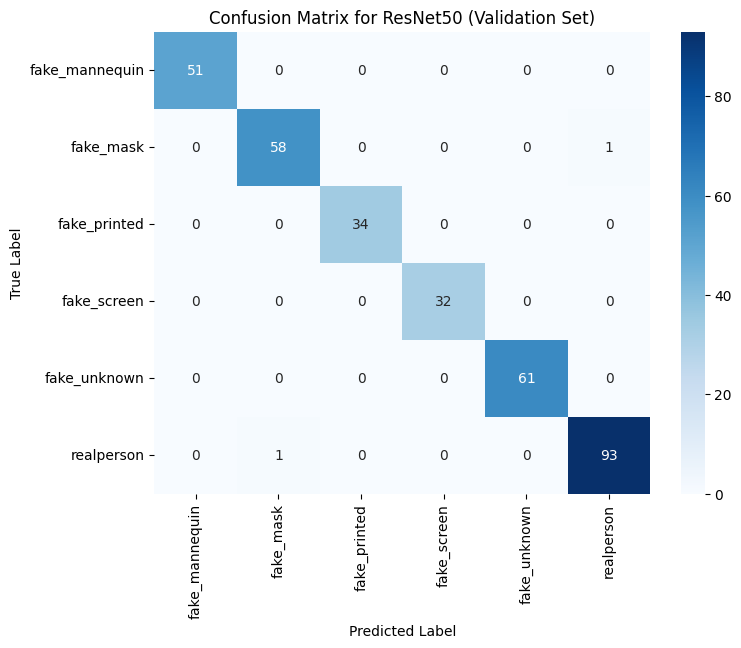

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Set model to evaluation mode
m1_final.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="Generating Confusion Matrix"): # Use val_loader for evaluation
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        outputs = m1_final(images)
        _, predicted = torch.max(outputs, 1)
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predicted.cpu().numpy())

# Generate confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=[idx_to_class[i] for i in sorted(idx_to_class.keys())],
            yticklabels=[idx_to_class[i] for i in sorted(idx_to_class.keys())])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix for ResNet50 (Validation Set)')
plt.show()

In [ ]:
from sklearn.metrics import classification_report, balanced_accuracy_score

# Calculate and print classification report
report = classification_report(all_labels, all_preds, target_names=[idx_to_class[i] for i in sorted(idx_to_class.keys())], output_dict=True)
print("Classification Report for ResNet50 (Validation Set):\n")

# Convert to DataFrame for better display
report_df = pd.DataFrame(report).transpose()
display(report_df)

# Calculate Balanced Accuracy
balanced_acc = balanced_accuracy_score(all_labels, all_preds)
print(f"\nBalanced Accuracy for ResNet50 (Validation Set): {balanced_acc:.4f}")

Classification Report for ResNet50 (Validation Set):



,precision,recall,f1-score,support
fake_mannequin,1.000000,1.000000,1.000000,51.000000
fake_mask,0.983051,0.983051,0.983051,59.000000
fake_printed,1.000000,1.000000,1.000000,34.000000
fake_screen,1.000000,1.000000,1.000000,32.000000
fake_unknown,1.000000,1.000000,1.000000,61.000000
realperson,0.989362,0.989362,0.989362,94.000000
accuracy,0.993958,0.993958,0.993958,0.993958
macro avg,0.995402,0.995402,0.995402,331.000000
weighted avg,0.993958,0.993958,0.993958,331.000000



Balanced Accuracy for ResNet50 (Validation Set): 0.9954


macro avg f1-score: This is the unweighted average of the F1-scores for each class. In this case, it's 0.9926.
weighted avg f1-score: This is the average of the F1-scores for each class, weighted by the number of true instances for each class. In this case, it's 0.9940.